In [2]:
import pandas as pd
import numpy as np 

In [3]:
df=pd.read_csv(r"C:\Users\subha\Downloads\customer_shopping_behavior.csv")

In [4]:
type(df)

pandas.core.frame.DataFrame

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [6]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [7]:
df['Review Rating']=df.groupby('Category')['Review Rating'].transform(lambda x:x.fillna(x.median()))

In [8]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [9]:
df.columns=df.columns.str.lower()

In [10]:
df.columns=df.columns.str.replace(' ','_')
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount_(usd)', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [11]:
df=df.rename(columns={'purchase_amount_(usd)':'purchase_amount'})

In [12]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [13]:
type(df)

pandas.core.frame.DataFrame

In [14]:
labels=['young_adult','adult','middle_aged','senior']
df['age_group']=pd.qcut(df['age'],q=4,labels=labels)

In [15]:
df[['age','age_group']].head(10)

,age,age_group
0,55,middle_aged
1,19,young_adult
2,50,middle_aged
3,21,young_adult
4,45,middle_aged
5,46,middle_aged
6,63,senior
7,27,young_adult
8,26,young_adult
9,57,middle_aged


In [16]:
df

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,promo_code_used,previous_purchases,payment_method,frequency_of_purchases,age_group
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly,middle_aged
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly,young_adult
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly,middle_aged
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly,young_adult
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually,middle_aged
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,2-Day Shipping,No,No,32,Venmo,Weekly,adult
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly,middle_aged
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Standard,No,No,24,Venmo,Quarterly,middle_aged
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,Express,No,No,24,Venmo,Weekly,adult


In [17]:
df['frequency_of_purchases'].unique()

array(['Fortnightly', 'Weekly', 'Annually', 'Quarterly', 'Bi-Weekly',
       'Monthly', 'Every 3 Months'], dtype=object)

In [18]:
purchase_map={
    'Fortnightly':14,
    'Weekly':7,
    'Annually':365,
    'Quarterly':90,
    'Bi-Weekly':14,
    'Monthly':30,
    'Every 3 Months':90
}

In [19]:
df['purchases_frequency_days']=df['frequency_of_purchases'].map(purchase_map)

In [20]:
df[['frequency_of_purchases','purchases_frequency_days']]

,frequency_of_purchases,purchases_frequency_days
0,Fortnightly,14
1,Fortnightly,14
2,Weekly,7
3,Weekly,7
4,Annually,365
...,...,...
3895,Weekly,7
3896,Bi-Weekly,14
3897,Quarterly,90
3898,Weekly,7


In [21]:
df[['discount_applied','promo_code_used']].head(10)

,discount_applied,promo_code_used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [22]:
(df['discount_applied']==df['promo_code_used']).all()

True

In [23]:
df.drop('promo_code_used',axis=1)

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchases_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,middle_aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,young_adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,middle_aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,young_adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,middle_aged,365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,2-Day Shipping,No,32,Venmo,Weekly,adult,7
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,Store Pickup,No,41,Bank Transfer,Bi-Weekly,middle_aged,14
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Standard,No,24,Venmo,Quarterly,middle_aged,90
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,Express,No,24,Venmo,Weekly,adult,7


In [24]:
df.shape

(3900, 20)

In [25]:
df.isnull().sum()

customer_id                 0
age                         0
gender                      0
item_purchased              0
category                    0
purchase_amount             0
location                    0
size                        0
color                       0
season                      0
review_rating               0
subscription_status         0
shipping_type               0
discount_applied            0
promo_code_used             0
previous_purchases          0
payment_method              0
frequency_of_purchases      0
age_group                   0
purchases_frequency_days    0
dtype: int64

In [26]:
df.duplicated().sum()

0

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   customer_id               3900 non-null   int64   
 1   age                       3900 non-null   int64   
 2   gender                    3900 non-null   object  
 3   item_purchased            3900 non-null   object  
 4   category                  3900 non-null   object  
 5   purchase_amount           3900 non-null   int64   
 6   location                  3900 non-null   object  
 7   size                      3900 non-null   object  
 8   color                     3900 non-null   object  
 9   season                    3900 non-null   object  
 10  review_rating             3900 non-null   float64 
 11  subscription_status       3900 non-null   object  
 12  shipping_type             3900 non-null   object  
 13  discount_applied          3900 non-null   object

In [28]:
df.describe()

,customer_id,age,purchase_amount,review_rating,previous_purchases,purchases_frequency_days
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750051,25.351538,89.133077
std,1125.977353,15.207589,23.685392,0.713590,14.447125,119.037566
min,1.000000,18.000000,20.000000,2.500000,1.000000,7.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000,14.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000,30.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000,90.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000,365.000000


In [29]:
print("Total Transactions:", len(df))
print("Total Purchase Amount:", df['purchase_amount'].sum())
print("Average Purchase Amount:", df['purchase_amount'].mean())
print("Average Review Rating:", df['review_rating'].mean())
print("Average Previous Purchases:", df['previous_purchases'].mean())

Total Transactions: 3900
Total Purchase Amount: 233081
Average Purchase Amount: 59.76435897435898
Average Review Rating: 3.750051282051282
Average Previous Purchases: 25.35153846153846


In [30]:
df[['purchase_amount', 'review_rating', 'previous_purchases']].describe()

,purchase_amount,review_rating,previous_purchases
count,3900.000000,3900.000000,3900.000000
mean,59.764359,3.750051,25.351538
std,23.685392,0.713590,14.447125
min,20.000000,2.500000,1.000000
25%,39.000000,3.100000,13.000000
50%,60.000000,3.800000,25.000000
75%,81.000000,4.400000,38.000000
max,100.000000,5.000000,50.000000


In [31]:
df['gender'].value_counts()

gender
Male      2652
Female    1248
Name: count, dtype: int64

In [32]:
df['gender'].value_counts(normalize=True)*100

gender
Male      68.0
Female    32.0
Name: proportion, dtype: float64

In [33]:
df['age'].describe()

count    3900.000000
mean       44.068462
std        15.207589
min        18.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        70.000000
Name: age, dtype: float64

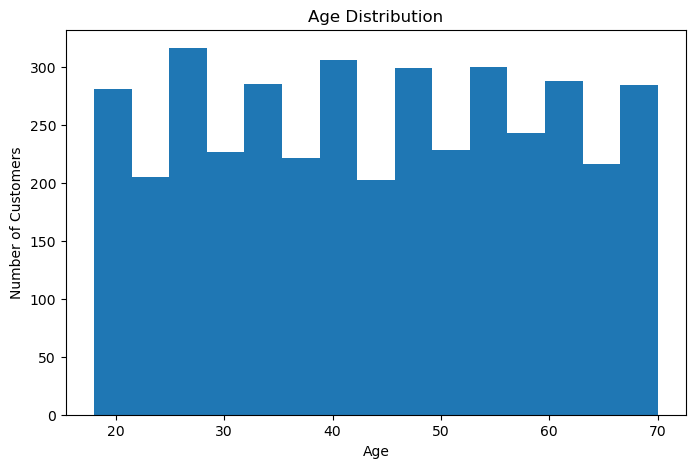

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=15)
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.title('Age Distribution')
plt.show()

In [35]:
df['age_group']

0       middle_aged
1       young_adult
2       middle_aged
3       young_adult
4       middle_aged
           ...     
3895          adult
3896    middle_aged
3897    middle_aged
3898          adult
3899    middle_aged
Name: age_group, Length: 3900, dtype: category
Categories (4, object): ['young_adult' < 'adult' < 'middle_aged' < 'senior']

In [36]:
df['age_group'].value_counts().sort_index()

age_group
young_adult    1028
adult           942
middle_aged     986
senior          944
Name: count, dtype: int64

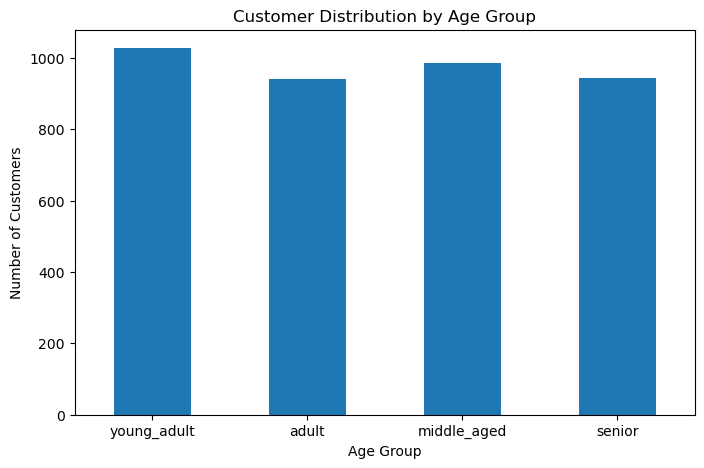

In [37]:
df['age_group'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.title('Customer Distribution by Age Group')
plt.xticks(rotation=0)
plt.show()

In [38]:
df['category'].value_counts()

category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

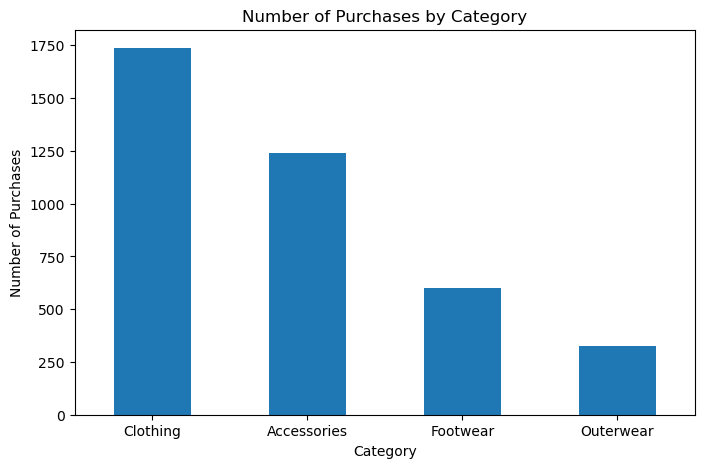

In [39]:
df['category'].value_counts().plot(
    kind='bar',
    figsize=(8,5)
)

plt.xlabel('Category')
plt.ylabel('Number of Purchases')
plt.title('Number of Purchases by Category')
plt.xticks(rotation=0)
plt.show()

In [40]:
category_sales = df.groupby('category')['purchase_amount'].sum().sort_values(ascending=False)

print(category_sales)

category
Clothing       104264
Accessories     74200
Footwear        36093
Outerwear       18524
Name: purchase_amount, dtype: int64


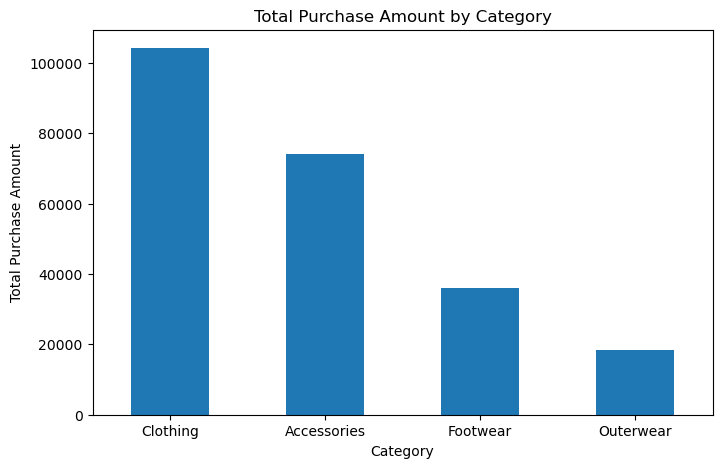

In [41]:
category_sales.plot(
    kind='bar',
    figsize=(8,5)
)

plt.xlabel('Category')
plt.ylabel('Total Purchase Amount')
plt.title('Total Purchase Amount by Category')
plt.xticks(rotation=0)
plt.show()

In [42]:
category_avg = df.groupby('category')['purchase_amount'].mean().sort_values(ascending=False)

print(category_avg)

category
Footwear       60.255426
Clothing       60.025331
Accessories    59.838710
Outerwear      57.172840
Name: purchase_amount, dtype: float64


In [43]:
item_counts = df['item_purchased'].value_counts()

print(item_counts.head(10))

item_purchased
Blouse        171
Jewelry       171
Pants         171
Shirt         169
Dress         166
Sweater       164
Jacket        163
Belt          161
Sunglasses    161
Coat          161
Name: count, dtype: int64


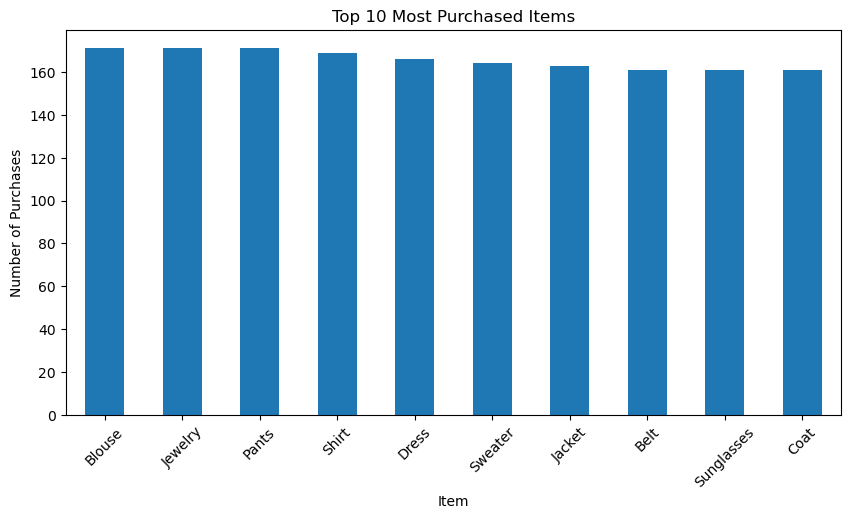

In [44]:
item_counts.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Item')
plt.ylabel('Number of Purchases')
plt.title('Top 10 Most Purchased Items')
plt.xticks(rotation=45)
plt.show()

In [45]:
item_sales = (
    df.groupby('item_purchased')['purchase_amount']
      .sum()
      .sort_values(ascending=False)
)

print(item_sales.head(10))

item_purchased
Blouse        10410
Shirt         10332
Dress         10320
Pants         10090
Jewelry       10010
Sunglasses     9649
Belt           9635
Scarf          9561
Sweater        9462
Shorts         9433
Name: purchase_amount, dtype: int64


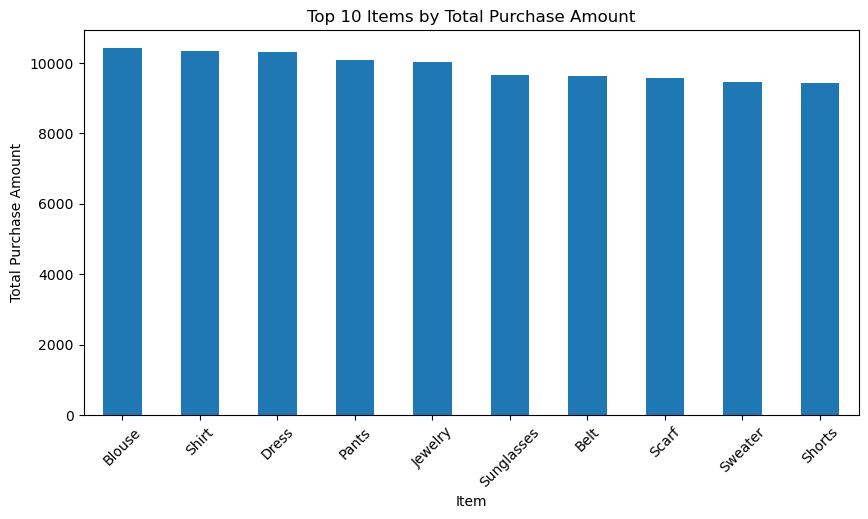

In [46]:
item_sales.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Item')
plt.ylabel('Total Purchase Amount')
plt.title('Top 10 Items by Total Purchase Amount')
plt.xticks(rotation=45)
plt.show()

In [47]:
location_counts = df['location'].value_counts()

print(location_counts.head(10))

location
Montana       96
California    95
Idaho         93
Illinois      92
Alabama       89
Minnesota     88
Nebraska      87
New York      87
Nevada        87
Maryland      86
Name: count, dtype: int64


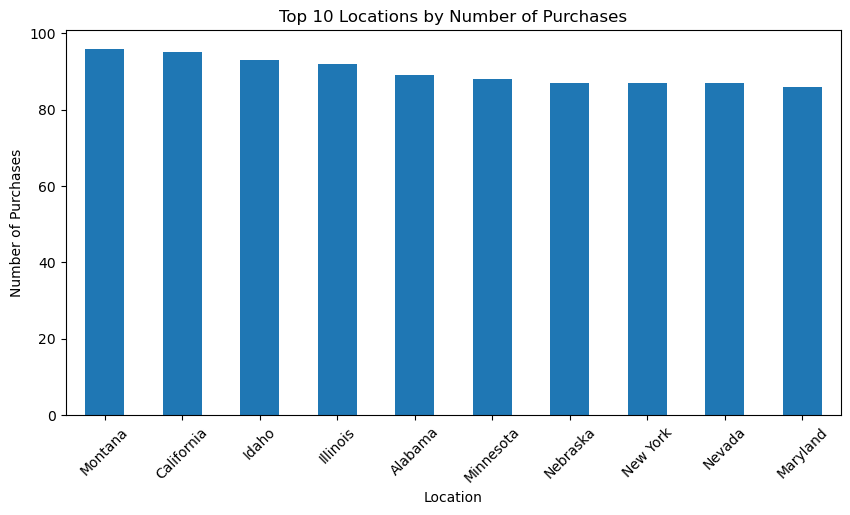

In [48]:
location_counts.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Location')
plt.ylabel('Number of Purchases')
plt.title('Top 10 Locations by Number of Purchases')
plt.xticks(rotation=45)
plt.show()

In [49]:
location_sales = (
    df.groupby('location')['purchase_amount']
      .sum()
      .sort_values(ascending=False)
)

print(location_sales.head(10))

location
Montana          5784
Illinois         5617
California       5605
Idaho            5587
Nevada           5514
Alabama          5261
New York         5257
North Dakota     5220
West Virginia    5174
Nebraska         5172
Name: purchase_amount, dtype: int64


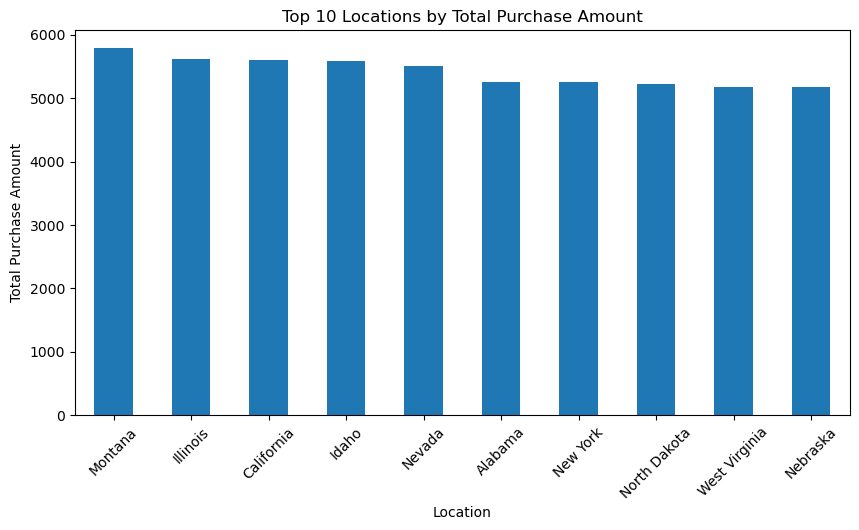

In [50]:
location_sales.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Location')
plt.ylabel('Total Purchase Amount')
plt.title('Top 10 Locations by Total Purchase Amount')
plt.xticks(rotation=45)
plt.show()

In [51]:
location_avg = (
    df.groupby('location')['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(location_avg.head(10))

location
Alaska           67.597222
Pennsylvania     66.567568
Arizona          66.553846
West Virginia    63.876543
Nevada           63.379310
Washington       63.328767
North Dakota     62.891566
Virginia         62.883117
Utah             62.577465
Michigan         62.095890
Name: purchase_amount, dtype: float64


In [52]:
season_counts = df['season'].value_counts()

print(season_counts)

season
Spring    999
Fall      975
Winter    971
Summer    955
Name: count, dtype: int64


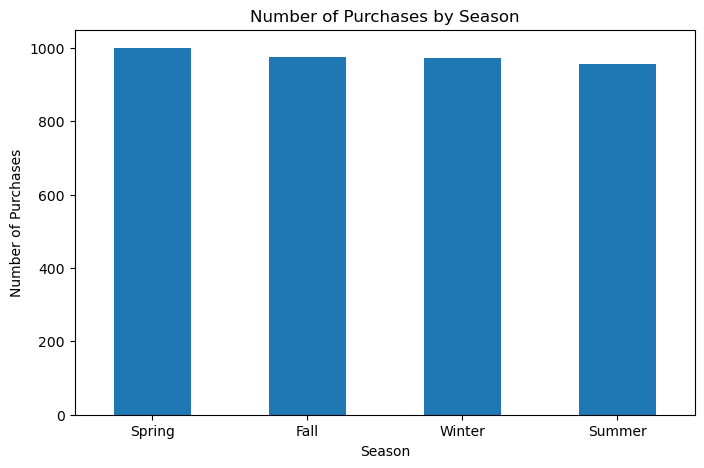

In [53]:
season_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Season')
plt.ylabel('Number of Purchases')
plt.title('Number of Purchases by Season')
plt.xticks(rotation=0)
plt.show()

In [54]:
season_sales = (
    df.groupby('season')['purchase_amount']
      .sum()
      .sort_values(ascending=False)
)

print(season_sales)

season
Fall      60018
Spring    58679
Winter    58607
Summer    55777
Name: purchase_amount, dtype: int64


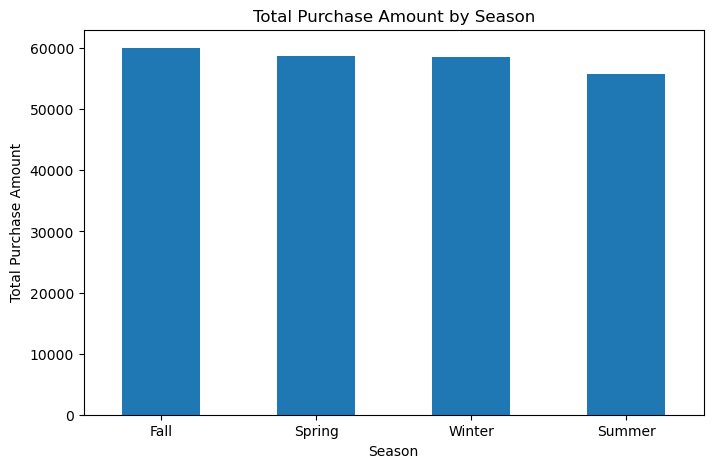

In [55]:
season_sales.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Season')
plt.ylabel('Total Purchase Amount')
plt.title('Total Purchase Amount by Season')
plt.xticks(rotation=0)
plt.show()

In [56]:
season_avg = (
    df.groupby('season')['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(season_avg)

season
Fall      61.556923
Winter    60.357364
Spring    58.737738
Summer    58.405236
Name: purchase_amount, dtype: float64


In [57]:
subscription_counts = df['subscription_status'].value_counts()

print(subscription_counts)

subscription_status
No     2847
Yes    1053
Name: count, dtype: int64


In [58]:
print(df['subscription_status'].value_counts(normalize=True) * 100)

subscription_status
No     73.0
Yes    27.0
Name: proportion, dtype: float64


In [59]:
subscription_sales = (
    df.groupby('subscription_status')['purchase_amount']
      .sum()
      .sort_values(ascending=False)
)

print(subscription_sales)

subscription_status
No     170436
Yes     62645
Name: purchase_amount, dtype: int64


In [60]:
subscription_avg = (
    df.groupby('subscription_status')['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(subscription_avg)

subscription_status
No     59.865121
Yes    59.491928
Name: purchase_amount, dtype: float64


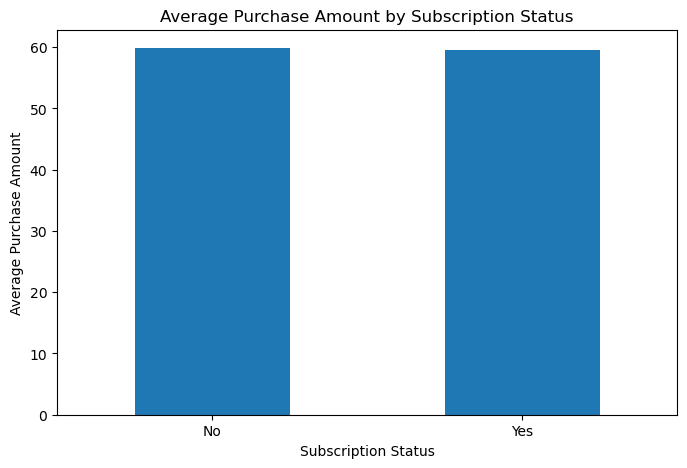

In [61]:
subscription_avg.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Subscription Status')
plt.ylabel('Average Purchase Amount')
plt.title('Average Purchase Amount by Subscription Status')
plt.xticks(rotation=0)
plt.show()

In [62]:
'promo_code_used' in df.columns

True

In [63]:
df = df.drop(columns='promo_code_used')

In [64]:
discount_counts = df['discount_applied'].value_counts()

print(discount_counts)

discount_applied
No     2223
Yes    1677
Name: count, dtype: int64


In [65]:
print(df['discount_applied'].value_counts(normalize=True) * 100)

discount_applied
No     57.0
Yes    43.0
Name: proportion, dtype: float64


In [66]:
discount_sales = (
    df.groupby('discount_applied')['purchase_amount']
      .sum()
      .sort_values(ascending=False)
)

print(discount_sales)

discount_applied
No     133670
Yes     99411
Name: purchase_amount, dtype: int64


In [67]:
discount_avg = (
    df.groupby('discount_applied')['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(discount_avg)

discount_applied
No     60.130454
Yes    59.279070
Name: purchase_amount, dtype: float64


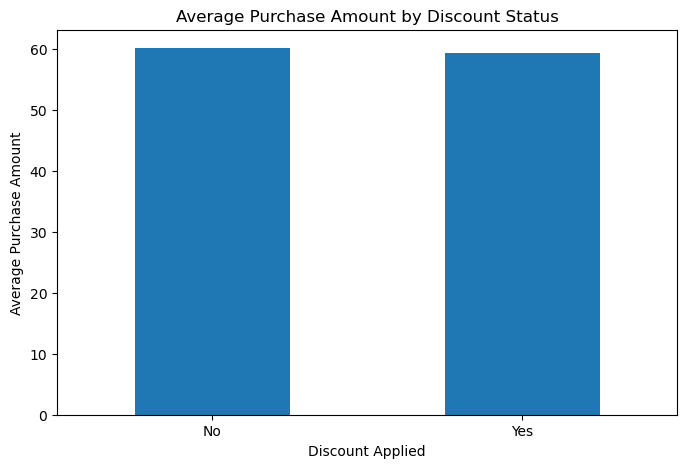

In [68]:
discount_avg.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Discount Applied')
plt.ylabel('Average Purchase Amount')
plt.title('Average Purchase Amount by Discount Status')
plt.xticks(rotation=0)
plt.show()

In [69]:
payment_counts = df['payment_method'].value_counts()

print(payment_counts)

payment_method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64


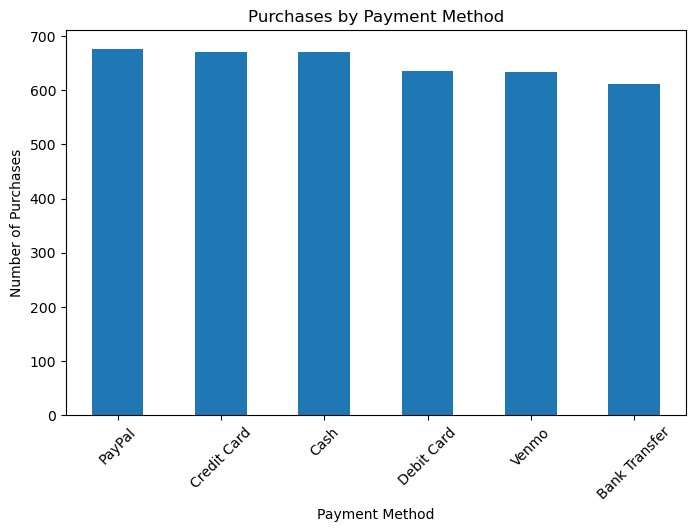

In [70]:
payment_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Payment Method')
plt.ylabel('Number of Purchases')
plt.title('Purchases by Payment Method')
plt.xticks(rotation=45)
plt.show()

In [71]:
payment_avg = (
    df.groupby('payment_method')['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(payment_avg)

payment_method
Debit Card       60.915094
Credit Card      60.074516
Bank Transfer    59.712418
Cash             59.704478
PayPal           59.245199
Venmo            58.949527
Name: purchase_amount, dtype: float64


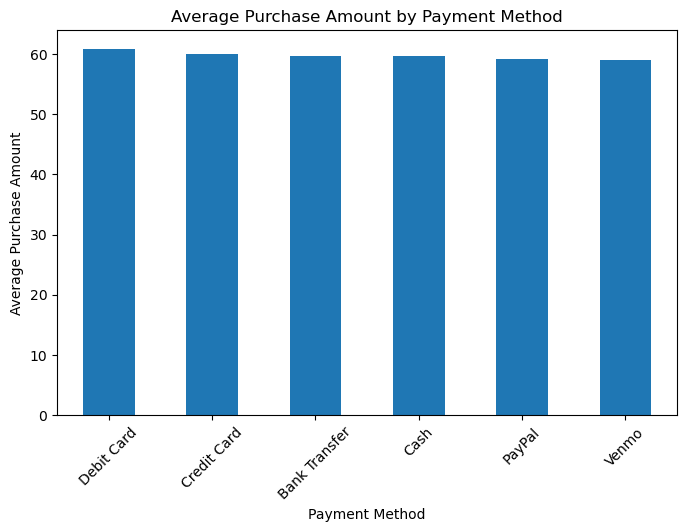

In [72]:
payment_avg.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Payment Method')
plt.ylabel('Average Purchase Amount')
plt.title('Average Purchase Amount by Payment Method')
plt.xticks(rotation=45)
plt.show()

In [73]:
frequency_counts = df['frequency_of_purchases'].value_counts()

print(frequency_counts)

frequency_of_purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539
Name: count, dtype: int64


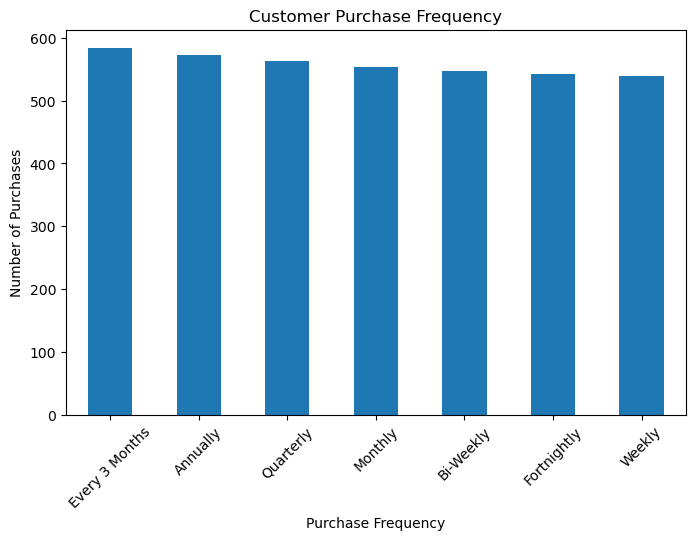

In [74]:
frequency_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Purchase Frequency')
plt.ylabel('Number of Purchases')
plt.title('Customer Purchase Frequency')
plt.xticks(rotation=45)
plt.show()

In [75]:
frequency_avg = (
    df.groupby('frequency_of_purchases')['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(frequency_avg)

frequency_of_purchases
Bi-Weekly         60.694698
Annually          60.173077
Every 3 Months    60.082192
Quarterly         59.984014
Monthly           59.330922
Fortnightly       59.053506
Weekly            58.972171
Name: purchase_amount, dtype: float64


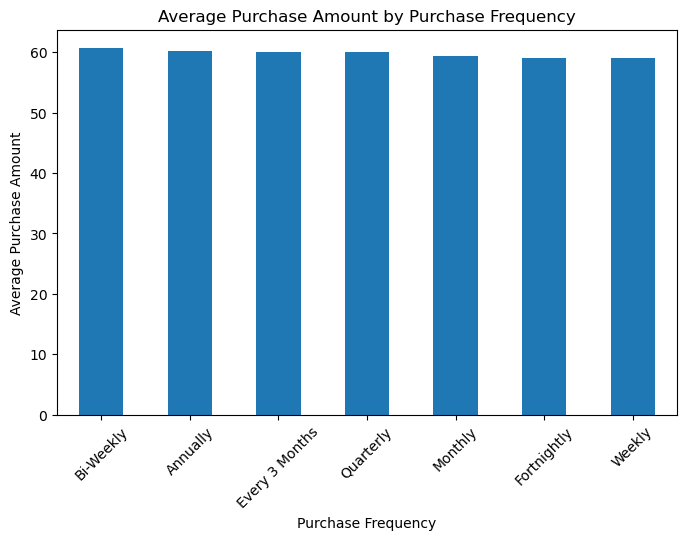

In [76]:
frequency_avg.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Purchase Frequency')
plt.ylabel('Average Purchase Amount')
plt.title('Average Purchase Amount by Purchase Frequency')
plt.xticks(rotation=45)
plt.show()

In [77]:
rating_counts = df['review_rating'].value_counts().sort_index()

print(rating_counts)

review_rating
2.5     66
2.6    158
2.7    154
2.8    136
2.9    166
3.0    162
3.1    156
3.2    152
3.3    146
3.4    182
3.5    152
3.6    147
3.7    168
3.8    159
3.9    162
4.0    181
4.1    148
4.2    169
4.3    147
4.4    158
4.5    139
4.6    170
4.7    148
4.8    144
4.9    162
5.0     68
Name: count, dtype: int64


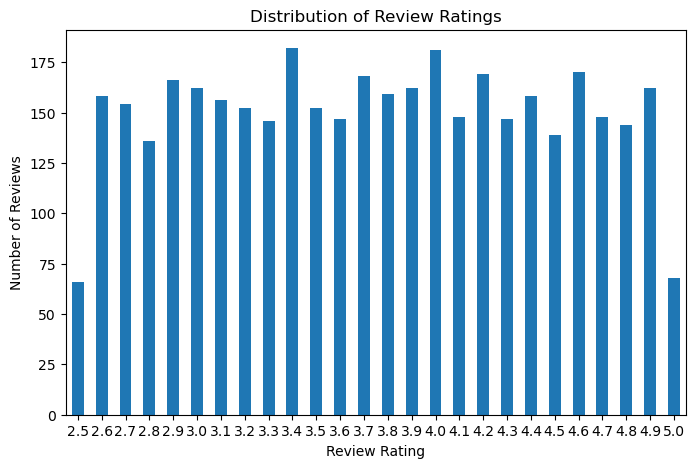

In [78]:
rating_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Review Rating')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Review Ratings')
plt.xticks(rotation=0)
plt.show()

In [79]:
rating_avg = (
    df.groupby('review_rating')['purchase_amount']
      .mean()
      .sort_index()
)

print(rating_avg)

review_rating
2.5    62.287879
2.6    59.765823
2.7    59.363636
2.8    57.066176
2.9    56.198795
3.0    60.728395
3.1    58.782051
3.2    61.315789
3.3    59.794521
3.4    59.005495
3.5    58.072368
3.6    57.081633
3.7    60.244048
3.8    61.132075
3.9    58.913580
4.0    59.237569
4.1    61.959459
4.2    60.757396
4.3    59.673469
4.4    60.525316
4.5    59.489209
4.6    57.311765
4.7    59.283784
4.8    61.881944
4.9    63.746914
5.0    64.352941
Name: purchase_amount, dtype: float64


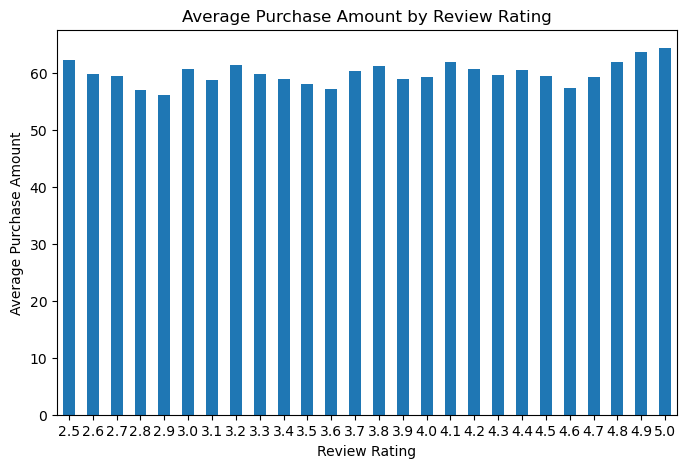

In [80]:
rating_avg.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Review Rating')
plt.ylabel('Average Purchase Amount')
plt.title('Average Purchase Amount by Review Rating')
plt.xticks(rotation=0)
plt.show()

In [81]:
age_group_avg = (
    df.groupby('age_group', observed=True)['purchase_amount']
      .mean()
      .sort_values(ascending=False)
)

print(age_group_avg)

age_group
young_adult    60.450389
middle_aged    60.037525
adult          59.424628
senior         59.070975
Name: purchase_amount, dtype: float64


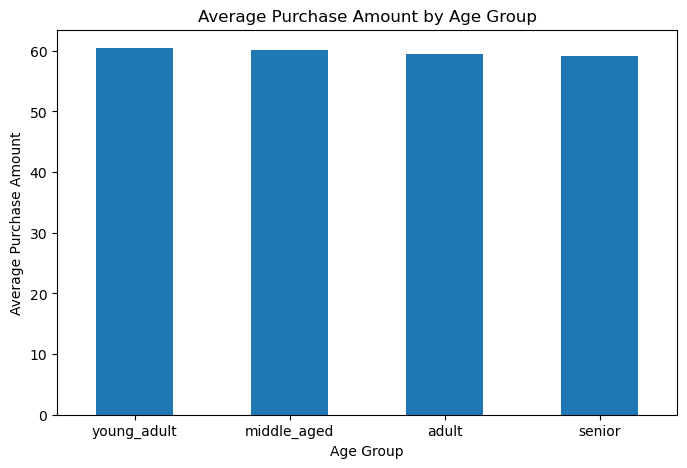

In [82]:
age_group_avg.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount')
plt.title('Average Purchase Amount by Age Group')
plt.xticks(rotation=0)
plt.show()

In [83]:
df.shape

(3900, 19)

In [84]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchases_frequency_days'],
      dtype='object')

In [86]:
df.to_csv("../data/customer_shopping_behavior_cleaned.csv", index=False)

In [87]:
import os
os.path.exists("../data/customer_shopping_behavior_cleaned.csv")

True

In [88]:
import os

print(os.path.abspath("../data/customer_shopping_behavior_cleaned.csv"))

C:\Users\subha\sales analysis\data\customer_shopping_behavior_cleaned.csv
